# Laboratorio 12. Memoria asociativa de Hopfield

Recuperación de tres patrones de 10×10 y una imagen de cámara de 64×64 con estados de píxel −1 y +1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def patrones_balanceados(n=10, m=10):
    horizontal = -np.ones((n, m))
    horizontal[:n//2, :] = 1
    vertical = -np.ones((n, m))
    vertical[:, :m//2] = 1
    tablero = np.where(np.indices((n, m)).sum(axis=0) % 2 == 0, 1, -1)
    return [horizontal, vertical, tablero]

# Pasamos la imagen a un vector y verificamos que solo tenga estados bipolares.
def vectorizar(imagen):
    vector = np.asarray(imagen, dtype=float).ravel()
    if not np.isin(vector, [-1, 1]).all():
        raise ValueError('Los estados deben ser -1 o +1')
    return vector

def pesos_hebb(patrones):
    patrones = np.array([vectorizar(p) for p in patrones])
    # Sumamos los productos exteriores y anulamos las conexiones de un píxel consigo mismo.
    W = patrones.T @ patrones / patrones.shape[1]
    np.fill_diagonal(W, 0)
    return W

def campo_local(W, s, i):
    return W[i] @ s

def actualizar_neurona(W, s, i):
    h = campo_local(W, s, i)
    previo = s[i]
    # En un empate conservamos el estado para evitar introducir ceros.
    s[i] = 1 if h > 0 else (-1 if h < 0 else previo)
    return -(s[i] - previo) * h

def energia(W, s):
    return -.5 * s @ W @ s

def agregar_ruido(s, fraccion, seed=42):
    if not 0 <= fraccion <= 1:
        raise ValueError('La fracción debe estar entre 0 y 1')
    ruido = vectorizar(s).copy()
    rng = np.random.default_rng(seed)
    indices = rng.choice(ruido.size, int(fraccion * ruido.size), replace=False)
    ruido[indices] *= -1
    return ruido

def recuperar(W, inicial, seed=42, max_barridos=30):
    rng = np.random.default_rng(seed)
    s = vectorizar(inicial).copy()
    energias = [energia(W, s)]
    estable = False
    for barrido in range(max_barridos):
        anterior = s.copy()
        # Visitamos todos los píxeles en un orden aleatorio nuevo en cada barrido.
        for i in rng.permutation(len(s)):
            cambio_energia = actualizar_neurona(W, s, i)
            energias.append(energias[-1] + cambio_energia)
        if np.array_equal(anterior, s):
            estable = True
            break
    # La actualización incremental evita recalcular un producto matricial completo por píxel.
    assert np.isclose(energias[-1], energia(W, s), atol=1e-7)
    return s, np.array(energias), estable

## 1. Recuperar los patrones

Los pesos son simétricos y su diagonal es cero. La actualización asincrónica cumple $\Delta E=-(s_i^{nuevo}-s_i^{viejo})h_i\leq0$. La energía disminuye o se mantiene, aunque el estado estable puede ser distinto al patrón buscado.

Patrón 0: error final=0.0%, estable=True
Patrón 1: error final=0.0%, estable=True
Patrón 2: error final=0.0%, estable=True


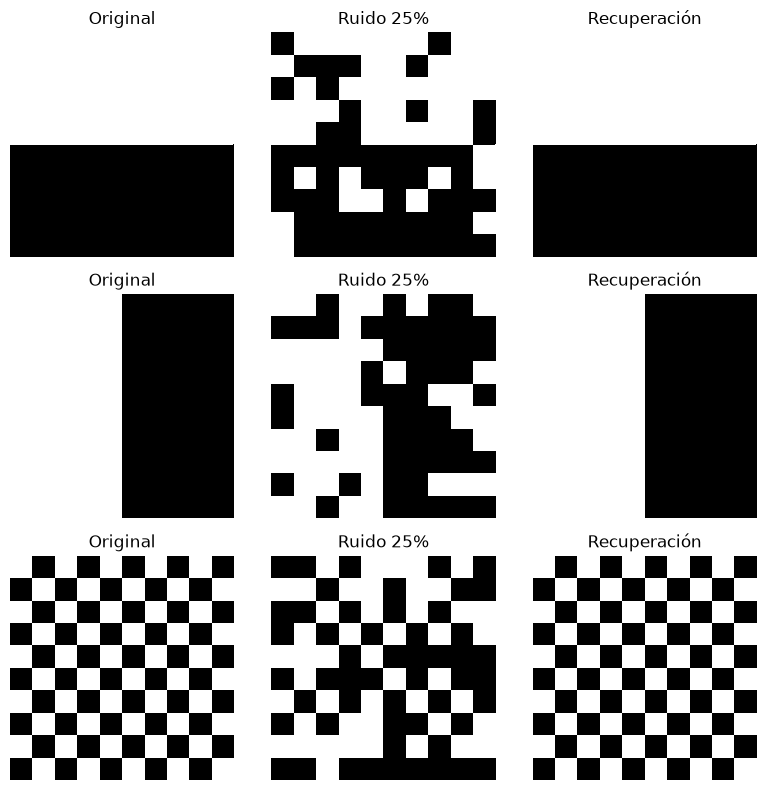

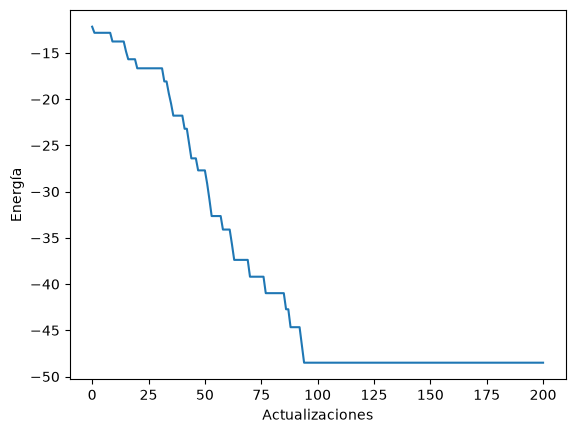

In [2]:
patrones = patrones_balanceados()
W = pesos_hebb(patrones)
assert np.allclose(W, W.T) and np.allclose(np.diag(W), 0)
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for fila, original in enumerate(patrones):
    perturbada = agregar_ruido(original, .25, seed=10 + fila)
    resultado, energias, estable = recuperar(W, perturbada)
    assert np.max(np.diff(energias)) <= 1e-8
    for ax, imagen, titulo in zip(axes[fila], [original, perturbada, resultado],
                                  ['Original', 'Ruido 25%', 'Recuperación']):
        ax.imshow(np.reshape(imagen, (10, 10)), cmap='gray', vmin=-1, vmax=1)
        ax.set_title(titulo)
        ax.axis('off')
    print(f'Patrón {fila}: error final={np.mean(resultado != original.ravel()):.1%}, estable={estable}')
plt.tight_layout()
plt.show()
plt.plot(energias)
plt.xlabel('Actualizaciones')
plt.ylabel('Energía')
plt.show()

## 2. Ruido y estados espurios

Repito cada nivel de ruido con varias semillas y registro si aparece el objetivo, otro patrón, su negativo o un estado espurio. Los negativos son memorias posibles por la simetría de signos.

,exacta,error,espurio_estable,negativo,estable
ruido,,,,,
0.00,1.0,0.00,0.0,0.00,1.0
0.10,1.0,0.00,0.0,0.00,1.0
0.25,1.0,0.00,0.0,0.00,1.0
0.40,0.8,0.05,0.2,0.00,1.0
0.50,0.0,0.50,0.0,0.55,1.0


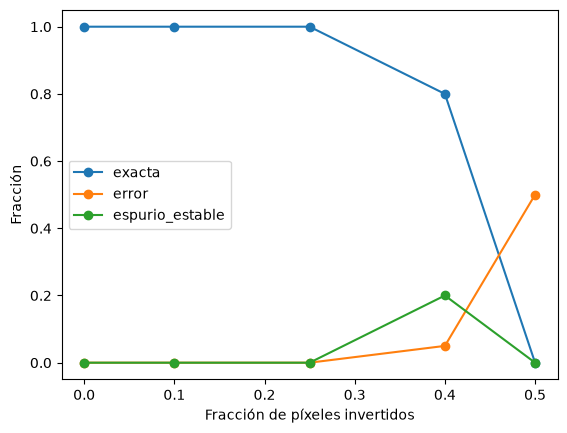

Estados finales distintos para la misma entrada: 3


In [3]:
memorias = np.array([p.ravel() for p in patrones])
filas = []
for ruido in [0., .1, .25, .4, .5]:
    for seed in range(20):
        inicial = agregar_ruido(patrones[2], ruido, seed)
        recuperada, energias, estable = recuperar(W, inicial, seed=100 + seed)
        es_memoria = any(np.array_equal(recuperada, p) for p in memorias)
        es_negativo = any(np.array_equal(recuperada, -p) for p in memorias)
        filas.append({'ruido': ruido, 'exacta': np.array_equal(recuperada, memorias[2]),
                      'error': np.mean(recuperada != memorias[2]),
                      'espurio_estable': estable and not es_memoria and not es_negativo,
                      'negativo': es_negativo, 'estable': estable})
tabla_ruido = pd.DataFrame(filas).groupby('ruido').mean()
display(tabla_ruido)
tabla_ruido[['exacta', 'error', 'espurio_estable']].plot(marker='o')
plt.xlabel('Fracción de píxeles invertidos')
plt.ylabel('Fracción')
plt.show()

# Mantenemos la misma entrada para aislar el efecto del orden de visita.
entrada_fija = agregar_ruido(patrones[2], .4, 27)
salidas = [recuperar(W, entrada_fija, seed=i)[0] for i in range(20)]
print('Estados finales distintos para la misma entrada:', len({s.tobytes() for s in salidas}))

Con 40 % de ruido se recuperó el patrón en 16 de 20 intentos y cuatro intentos terminaron en estados espurios estables. Con 50 % no hubo recuperaciones exactas. Una misma entrada produjo tres estados finales al cambiar el orden de actualización, así que ese orden sí puede influir.

Al guardar varias imágenes hay interferencia; la capacidad aproximada de 0.138 N supone patrones aleatorios y no garantiza recuperar imágenes correlacionadas.

Actualizar todas las neuronas a la vez puede producir ciclos. El descenso de energía anterior corresponde a actualizar una por una.

In [4]:
# Un ejemplo de dos neuronas muestra el ciclo de una actualización sincrónica.
W_dos = np.array([[0., 1.], [1., 0.]])
s = np.array([1., -1.])
for paso in range(4):
    print('Paso', paso, 'estado', s, 'energía', energia(W_dos, s))
    s = np.where(W_dos @ s >= 0, 1., -1.)
asincrono, energia_dos, estable = recuperar(W_dos, [1, -1])
print('Resultado asincrónico:', asincrono, '| estable:', estable)

Paso 0 estado [ 1. -1.] energía 1.0
Paso 1 estado [-1.  1.] energía 1.0
Paso 2 estado [ 1. -1.] energía 1.0
Paso 3 estado [-1.  1.] energía 1.0
Resultado asincrónico: [1. 1.] | estable: True


## 3. Imagen de cámara

Reduzco la imagen a 64×64 y uso su intensidad media como umbral para convertirla a estados bipolares.

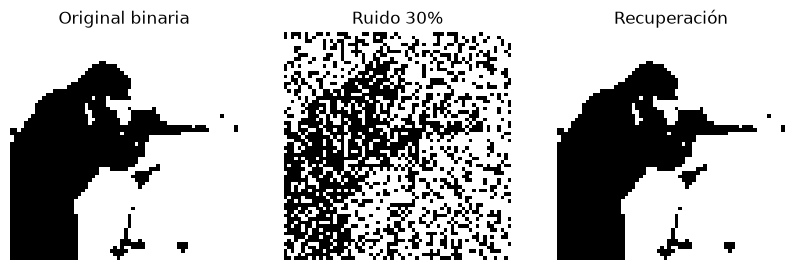

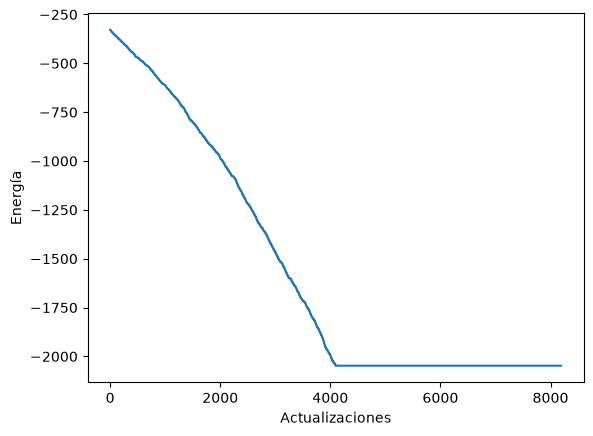

Error de píxeles: 0.0
Estado estable: True


In [2]:
from skimage import data
from skimage.transform import resize

imagen = resize(data.camera(), (64, 64), anti_aliasing=True)
binaria = np.where(imagen > imagen.mean(), 1., -1.)
W_imagen = pesos_hebb([binaria])
perturbada = agregar_ruido(binaria, .30, seed=123)
recuperada, energia_imagen, estable = recuperar(W_imagen, perturbada)
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
for ax, img, titulo in zip(axes, [binaria, perturbada, recuperada],
                           ['Original binaria', 'Ruido 30%', 'Recuperación']):
    ax.imshow(np.reshape(img, (64, 64)), cmap='gray')
    ax.set_title(titulo)
    ax.axis('off')
plt.show()
plt.plot(energia_imagen)
plt.xlabel('Actualizaciones')
plt.ylabel('Energía')
plt.show()
print('Error de píxeles:', np.mean(recuperada != binaria.ravel()))
print('Estado estable:', estable)
assert np.max(np.diff(energia_imagen)) <= 1e-7